In [ ]:
from pathlib import Path

fig_dir = Path(r"C:\Users\Marco\Desktop\SuSChemE_Figures")
fig_dir.mkdir(parents=True, exist_ok=True)

print("Folder exists:", fig_dir.exists())
print("Saving figures to:", fig_dir)

In [ ]:
#!/usr/bin/env python3
"""
Simple script to plot actual solar generation observations with projection lines.
"""
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


def plot_actual_solar_with_projections():
    """Plot the actual solar generation observations with projection lines."""
    # Paths relative to project root (parent of code/)
    project_root = Path("C:/Users/Marco/Downloads/solar_report_filled.csv").resolve().parent.parent
    data_path = project_root / "solar_report_filled.csv"
    graphs_dir = project_root / "graphs"

    # Load the data
    df = pd.read_csv("C:/Users/Marco/Downloads/solar_report_filled.csv")
    
    # Clean column names - stri
    # p all whitespace
    df.columns = df.columns.str.strip()
    
    # Get the actual observations (remove rows where "Actually got" is NaN)
    actual_data = df[df['Actually got'].notna()].copy()
    
    # Filter for current policy projections (excluding 2023 WEO)
    # Handle both 'cur' and 'Cur' variations, and strip whitespace from pol column
    cur_data = df[(df['pol'].str.strip().str.lower() == 'cur') & (df['Year'] != 2023)]
    
    print("Actual solar generation data:")
    print(actual_data[['Year', 'Actually got']])
    print("\nCur projection data:")
    print(cur_data[['Year', '2020', '2025', '2030', '2035']])
    # , '2040', '2050'
    # Create the plot
    plt.figure(figsize=(12, 8))

    # Projection line color: vibrant orange (good contrast, reads clearly)
    proj_color = '#E67E22'  # rich orange; alternatives: '#D35400' (darker), '#F39C12' (lighter)

    # Plot the actual observations as a black line with markers
    plt.plot(actual_data['Year'], actual_data['Actually got'], 
             'ko-', linewidth=2, markersize=6, label='Actual Solar Generation')
    
    # Add annotation for the 2025 point
    plt.annotate('2025 (projected)', xy=(2025, 2718), xytext=(2023, 2800),
                fontsize=10, ha='center')
    
    # Draw projection lines for each WEO year
    for _, row in cur_data.iterrows():
        weo_year = row['Year']
        projections = []
        
        # Collect all projection years and values (including 2040 and 2050): '2040', '2050'
        for year_col in ['2020', '2025', '2030', '2035']:
            if pd.notna(row[year_col]):
                try:
                    value = float(row[year_col])
                    projections.append((int(year_col), value))
                except (ValueError, TypeError):
                    continue
        
        if len(projections) > 0:
            print(f"Drawing {weo_year} WEO projections: {projections}")
            
            # Find the actual observation year to start the line from
            actual_year = None
            for _, actual_row in actual_data.iterrows():
                if actual_row['Year'] == weo_year:
                    actual_year = weo_year
                    break
            
            if actual_year is not None:
                # Draw line from actual observation to first projection
                if len(projections) > 0:
                    first_proj_year, first_proj_value = projections[0]
                    plt.plot([actual_year, first_proj_year], [actual_data[actual_data['Year'] == actual_year]['Actually got'].iloc[0], first_proj_value],
                            color=proj_color, linewidth=2, alpha=0.9)
                    
                    # Draw lines between subsequent projections
                    for i in range(len(projections) - 1):
                        year1, value1 = projections[i]
                        year2, value2 = projections[i + 1]
                        plt.plot([year1, year2], [value1, value2],
                                color=proj_color, linewidth=2, alpha=0.9)
                    
                    # Add markers for projection points
                    for year, value in projections:
                        plt.scatter(year, value, color=proj_color, s=50, alpha=0.9, edgecolors='black', linewidth=1)

    # Customize the plot
    # plt.title('World Solar PV Generation vs. International Energy Agency’s Annual Predictions', fontsize=18, fontweight='bold')
    plt.xlabel('Year', fontsize=12)
    plt.ylabel('Solar Generation (TWh)', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')
    
    # Set x-axis limits to show predictions through 2050
    plt.xlim(2009, 2035)

    # Build x-axis tick years from data and projection years , 2040, 2050
    all_years = sorted(list(set(list(actual_data['Year']) + [2020, 2025, 2030, 2035])))
    plt.xticks(all_years)

    # Create graphs directory if it doesn't exist
    graphs_dir.mkdir(exist_ok=True)

    # --- Linear version ---
    plt.ylim(bottom=0, top=25000)
    plt.gca().set_yscale('linear')  # ensure linear (no log)
    # Customize x-axis labels to use abbreviated years
    x_ticks = plt.xticks()[0]
    x_labels = []
    for year in x_ticks:
        if year >= 2030:
            x_labels.append(str(int(year)))  # Full year for 2030+
        else:
            x_labels.append(str(int(year))[-2:])  # Abbreviated for years < 2030
    plt.xticks(x_ticks, x_labels)
    # plt.figtext(0.98, 0.02, 'Adapted from EIA solar projections' ,ha='right', va='bottom', fontsize=10, style='italic')
    label_linear = plt.figtext(0.02, 0.98, 'Linear scale', ha='left', va='top', fontsize=9, style='italic', color='gray')
    plt.tight_layout()
    plt.savefig(graphs_dir / "solar_generation_with_projections.png", dpi=300, bbox_inches='tight')
    print("Plot saved (linear):", graphs_dir / "solar_generation_with_projections.png")

    # --- Log version ---
    plt.ylim(bottom=10, top=25000)
    plt.yscale('log')
    plt.grid(True, alpha=0.3, which='major')
    plt.minorticks_on()
    plt.grid(True, alpha=0.1, which='minor')
    # Re-apply x-axis labels after scale change
    x_ticks = plt.xticks()[0]
    x_labels = []
    for year in x_ticks:
        if year >= 2030:
            x_labels.append(str(int(year)))
        else:
            x_labels.append(str(int(year))[-2:])
    plt.xticks(x_ticks, x_labels)
    # Reduce y-axis tick crowding on log scale
    y_ticks = plt.yticks()[0]
    plt.yticks(y_ticks[::2])
    label_linear.remove()  # so log version doesn't show "Linear scale"
    plt.figtext(0.02, 0.98, 'Log scale', ha='left', va='top', fontsize=9, style='italic', color='gray')
    plt.tight_layout()
    plt.savefig(graphs_dir / "solar_generation_with_projectionsLog.png", dpi=300, bbox_inches='tight')
    print("Plot saved (log):", graphs_dir / "solar_generation_with_projectionsLog.png")
    
    # Show the plot
    plt.show()


if __name__ == "__main__":
    plot_actual_solar_with_projections()

In [ ]:
import matplotlib.pyplot as plt

# -----------------------------
# Approximate actual solar generation data
# Units: TWh
# -----------------------------
actual_years = list(range(2009, 2026))

actual_generation = [
    25,    # 2009
    38,    # 2010
    65,    # 2011
    100,   # 2012
    135,   # 2013
    185,   # 2014
    250,   # 2015
    315,   # 2016
    445,   # 2017
    600,   # 2018
    690,   # 2019
    830,   # 2020
    1030,  # 2021
    1290,  # 2022
    1600,  # 2023
    2100,  # 2024
    2720   # 2025 projected
]

# -----------------------------
# Approximate IEA annual forecast lines
# Each list represents one forecast vintage.
# Format:
# forecast_year: [(x1, y1), (x2, y2), ...]
# -----------------------------
iea_forecasts = {
    2009: [(2009, 25), (2020, 120), (2030, 250), (2035, 380)],
    2010: [(2010, 38), (2020, 140), (2030, 290), (2035, 420)],
    2011: [(2011, 65), (2020, 160), (2030, 330), (2035, 520)],
    2012: [(2012, 100), (2020, 200), (2030, 450), (2035, 680)],
    2013: [(2013, 135), (2020, 250), (2030, 580), (2035, 850)],
    2014: [(2014, 185), (2020, 300), (2030, 750), (2035, 1050)],
    2015: [(2015, 250), (2020, 350), (2030, 950), (2035, 1500)],
    2016: [(2016, 315), (2020, 420), (2030, 1400), (2035, 2250)],
    2017: [(2017, 445), (2020, 520), (2030, 1750), (2035, 3000)],
    2018: [(2018, 600), (2020, 550), (2030, 2300), (2035, 4100)],
    2019: [(2019, 690), (2020, 720), (2030, 2800), (2035, 4500)],
    2020: [(2020, 830), (2030, 3500), (2035, 5100)],
    2021: [(2021, 1030), (2030, 4000), (2035, 6000)],
}

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(16, 9))

# Plot IEA forecast lines
for vintage, points in iea_forecasts.items():
    years = [p[0] for p in points]
    values = [p[1] for p in points]
    
    plt.plot(
        years,
        values,
        color="gold",
        linewidth=2.5,
        marker="o",
        markersize=6,
        markeredgecolor="black",
        alpha=0.9
    )

# Plot actual solar generation
plt.plot(
    actual_years,
    actual_generation,
    color="black",
    linewidth=3,
    marker="o",
    markersize=7,
    label="Actual Solar Generation"
)

# Annotate projected 2025 point
plt.annotate(
    "2025 (projected)",
    xy=(2025, actual_generation[-1]),
    xytext=(2021.6, 2800),
    fontsize=13,
    arrowprops=dict(arrowstyle="-", color="black", lw=0)
)

# Formatting
# plt.title(
#     "World Solar PV Generation vs. International Energy Agency’s Annual Predictions",
#     fontsize=22,
#     fontweight="bold"
# )

plt.xlabel("Year", fontsize=15)
plt.ylabel("Solar Generation (TWh)", fontsize=15)

plt.xlim(2009, 2035)
plt.ylim(0, 6000)

plt.xticks(
    list(range(2009, 2026)) + [2030, 2035],
    [str(y)[-2:] if y < 2030 else str(y) for y in list(range(2009, 2026)) + [2030, 2035]],
    fontsize=12
)

plt.yticks([0, 2000, 4000, 6000], fontsize=12)

plt.grid(True, alpha=0.3)
plt.legend(loc="upper left", fontsize=13)

# # Credit text
# plt.text(
#     2034.8,
#     -350,
#     "Recreated schematic based on uploaded figure",
#     ha="right",
#     fontsize=11,
#     style="italic"
# )

plt.tight_layout()
plt.show()

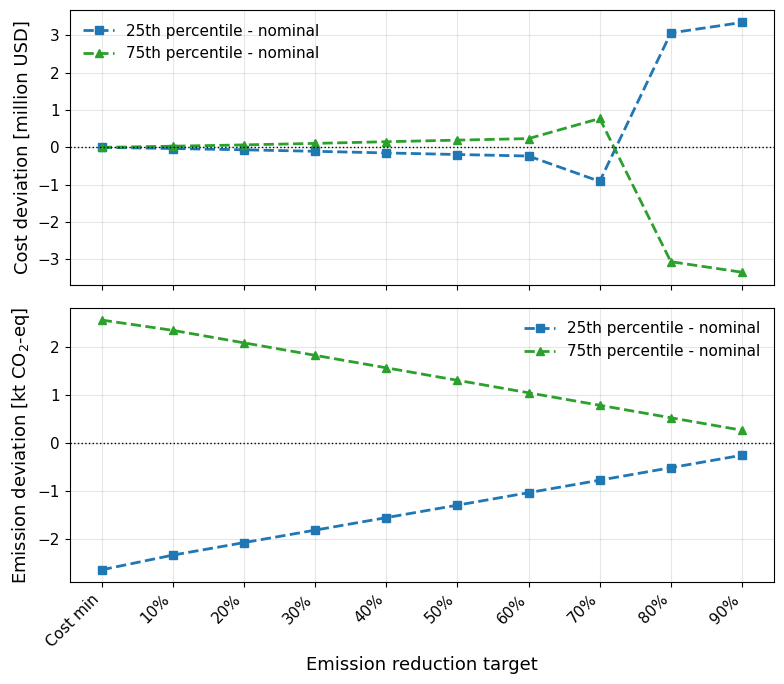

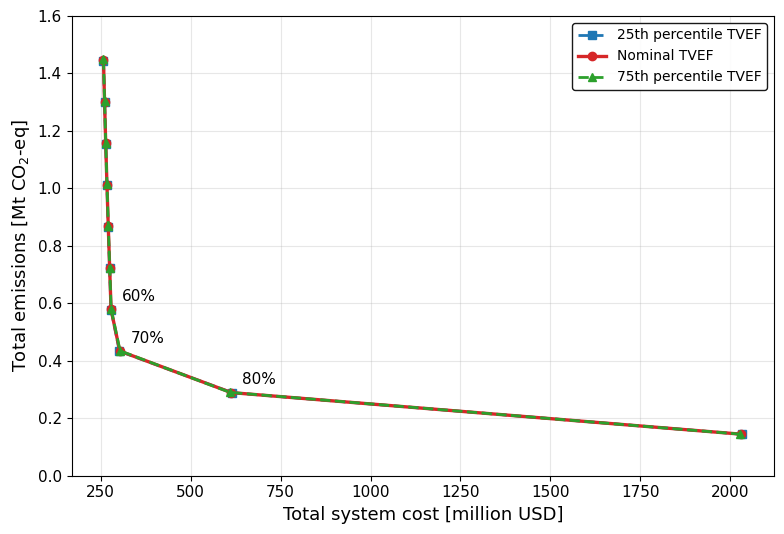

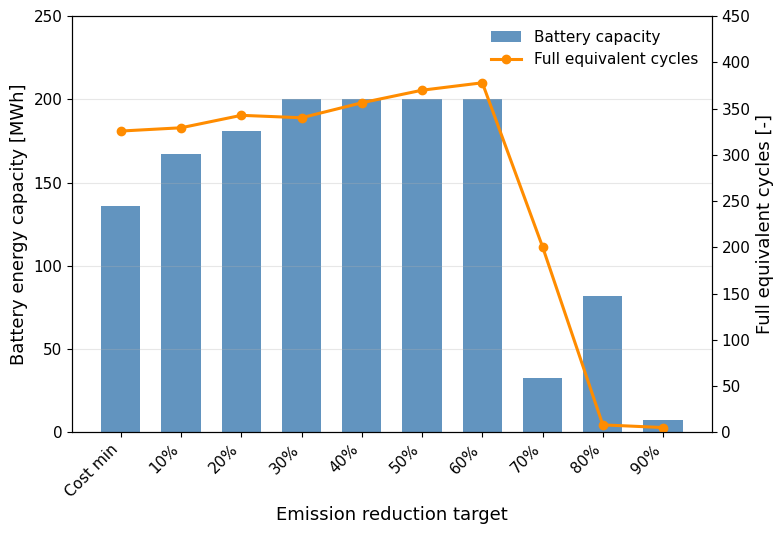

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Global formatting
# ============================================================
plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11
})

# ============================================================
# 2. Save directory
# ============================================================
fig_dir = Path(r"C:\Users\marcopdsousa\Documents\energiapy\ChemSus Conference\Graphs")
fig_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 3. Data
# ============================================================
scenarios = [
    "Cost min", "10%", "20%", "30%", "40%",
    "50%", "60%", "70%", "80%", "90%"
]

x_numeric = list(range(len(scenarios)))

nominal = pd.DataFrame({
    "scenario": scenarios,
    "reduction_frac": [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    "cost_USD": [
        257650376.5,
        260718507.6,
        263922530.7,
        267352371.8,
        271023383.9,
        274870366.7,
        278781792.7,
        303004501.7,
        613038179.2,
        2029496836
    ],
    "emissions_kg": [
        1446610978,
        1301908442,
        1157251948,
        1012595455,
        867938961,
        723282467.5,
        578625974,
        433969480.5,    
        289312987,
        144656493.5

    ],
    "battery_MWh": [
        135.8376548,
        167.0167545,
        181.2103783,
        200,
        200,
        200,
        200,
        32.66170776,
        82.1004389,
        7.42524573  


    ],
    "cycles": [
        325.64,
        329.1727026,
        342.6301926,
        340.0178974,
        356.2046316,
        369.7904776,
        377.8088693,
        200.5074033,
        8.020051187,
        5.148578876
    ],
})

q25 = pd.DataFrame({
    "scenario": scenarios,
    "reduction_frac": [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    "cost_USD": [
        257650376.5,
        260687700.2,
        263857147.3,
        267247587.7,
        270874340.1,
        274679454.8,
        278550233.4,
        302092995.7,
        616105046.1,
        2032843206
    ],
    "emissions_kg": [
       1443965726,
       1299569153,
       1155172581,
       1010776008,
       866379435.6,
       721982863,
       577586290.4,
       433189717.8,
       288793145.2,
       144396572.6
    ],
})

q75 = pd.DataFrame({
    "scenario": scenarios,
    "reduction_frac": [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    "cost_USD": [
        257650376.5,
        260749827.1,
        263989054.3,
        267459095.7,
        271175129.5,
        275064499.3,
        279017197.8,
        303778561.2,
        609975000.2,
        2026151482
    ],
    "emissions_kg": [
    1449164144,
    1304247730,
    1159331315,
    1014414901,
    869498486.4,
    724582072,
    579665657.6,
    434749243.2,
    289832828.8,
    144916414.4
    ],
})



# ============================================================
# 4. Unit conversion
# ============================================================
for df in [nominal, q25, q75]:
    df["cost_MUSD"] = df["cost_USD"] / 1e6
    df["emissions_Mt"] = df["emissions_kg"] / 1e9

# ============================================================
# 5. Figure 1: Pareto curve without GWP-min values
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Save directory
# ============================================================
fig_dir = Path(r"C:\Users\marcopdsousa\Documents\energiapy\ChemSus Conference\Graphs")
fig_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. Build deviation table relative to nominal
# ============================================================
deviation_df = pd.DataFrame({
    "scenario": nominal["scenario"],
    "q25_cost_dev_MUSD": (q25["cost_USD"] - nominal["cost_USD"]) / 1e6,
    "q75_cost_dev_MUSD": (q75["cost_USD"] - nominal["cost_USD"]) / 1e6,
    "q25_emis_dev_kt": (q25["emissions_kg"] - nominal["emissions_kg"]) / 1e6,
    "q75_emis_dev_kt": (q75["emissions_kg"] - nominal["emissions_kg"]) / 1e6,
})

x_numeric = list(range(len(deviation_df)))
scenario_labels = deviation_df["scenario"].tolist()

# ============================================================
# 3. Plot deviations from nominal case
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# -------------------------------
# Top plot: Cost deviation
# -------------------------------
ax1.plot(
    x_numeric,
    deviation_df["q25_cost_dev_MUSD"],
    marker="s",
    linestyle="--",
    linewidth=2.0,
    markersize=5.5,
    color="tab:blue",
    label="25th percentile - nominal"
)

ax1.plot(
    x_numeric,
    deviation_df["q75_cost_dev_MUSD"],
    marker="^",
    linestyle="--",
    linewidth=2.0,
    markersize=5.5,
    color="tab:green",
    label="75th percentile - nominal"
)

ax1.axhline(0, color="black", linewidth=1.0, linestyle=":")
ax1.set_ylabel("Cost deviation [million USD]")
ax1.grid(True, alpha=0.3)
ax1.legend(frameon=False, loc="best")

# -------------------------------
# Bottom plot: Emissions deviation
# -------------------------------
ax2.plot(
    x_numeric,
    deviation_df["q25_emis_dev_kt"],
    marker="s",
    linestyle="--",
    linewidth=2.0,
    markersize=5.5,
    color="tab:blue",
    label="25th percentile - nominal"
)

ax2.plot(
    x_numeric,
    deviation_df["q75_emis_dev_kt"],
    marker="^",
    linestyle="--",
    linewidth=2.0,
    markersize=5.5,
    color="tab:green",
    label="75th percentile - nominal"
)

ax2.axhline(0, color="black", linewidth=1.0, linestyle=":")
ax2.set_ylabel("Emission deviation [kt CO$_2$-eq]")
ax2.set_xlabel("Emission reduction target")
ax2.set_xticks(x_numeric)
ax2.set_xticklabels(scenario_labels, rotation=45, ha="right")
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=False, loc="best")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_base_case_deviation_from_nominal.png",
    dpi=600,
    bbox_inches="tight"
)
fig.savefig(
    fig_dir / "figure_base_case_deviation_from_nominal.pdf",
    bbox_inches="tight"
)

plt.show()

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    q25["cost_MUSD"],
    q25["emissions_Mt"],
    marker="s",
    linestyle="--",
    markersize=5.5,
    linewidth=2.0,
    color="tab:blue",
    label="25th percentile TVEF"
)

ax.plot(
    nominal["cost_MUSD"],
    nominal["emissions_Mt"],
    marker="o",
    linestyle="-",
    markersize=6,
    linewidth=2.4,
    color="tab:red",
    label="Nominal TVEF"
)

ax.plot(
    q75["cost_MUSD"],
    q75["emissions_Mt"],
    marker="^",
    linestyle="--",
    markersize=5.5,
    linewidth=2.0,
    color="tab:green",
    label="75th percentile TVEF"
)

annotation_points = ["60%", "70%", "80%"]

for _, row in nominal.iterrows():
    if row["scenario"] in annotation_points:
        ax.annotate(
            row["scenario"],
            xy=(row["cost_MUSD"], row["emissions_Mt"]),
            xytext=(8, 6),
            textcoords="offset points",
            fontsize=11
        )

ax.set_xlabel("Total system cost [million USD]")
ax.set_ylabel("Total emissions [Mt CO$_2$-eq]")
ax.set_ylim(0, 1.6)
ax.grid(True, alpha=0.3)

ax.legend(
    frameon=True,
    loc="upper right",
    fontsize=10,
    framealpha=0.9,
    edgecolor="black"
)

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_2a_base_case_quantile_cost_emissions_pareto.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_2a_base_case_quantile_cost_emissions_pareto.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. Figure 2: Battery capacity and cycles
# ============================================================
fig, ax1 = plt.subplots(figsize=(8, 5.5))

bar_color = "steelblue"
line_color = "darkorange"

ax1.bar(
    x_numeric,
    nominal["battery_MWh"],
    width=0.65,
    color=bar_color,
    alpha=0.85,
    label="Battery capacity"
)

ax1.set_xlabel("Emission reduction target")
ax1.set_ylabel("Battery energy capacity [MWh]")
ax1.set_xticks(x_numeric)
ax1.set_xticklabels(scenarios, rotation=45, ha="right")
ax1.set_ylim(0, 250)
ax1.grid(True, axis="y", alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    x_numeric,
    nominal["cycles"],
    marker="o",
    markersize=6,
    linewidth=2.2,
    color=line_color,
    label="Full equivalent cycles"
)

ax2.set_ylabel("Full equivalent cycles [-]")
ax2.set_ylim(0, 450)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    frameon=False,
    loc="upper right"
)

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_2b_base_case_battery_capacity_cycles.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_2b_base_case_battery_capacity_cycles.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
import os
print(os.getcwd())

In [ ]:
import matplotlib.pyplot as plt

# Sample data
x = [1.35, 1.443, 1.546, 1.625, 1.716, 1.807, 1.898, 1.989, 2.025, 2.044, 2.062, 2.080, 2.098, 2.116, 2.135, 2.162]
x2 = [1.35, 1.449, 1.546, 1.644, 1.741, 1.838, 1.935, 2.032, 2.071, 2.090, 2.110, 2.129, 2.149]
y1 = [19.950, 18.953, 17.955, 16.958, 15.960, 14.963, 13.965, 12.968, 12.569, 12.369, 12.170, 11.970, 11.771, 11.571, 11.372, 11.145]   # First dataset
y2 = [16.103 ,15.298, 14.493, 13.688, 12.882, 12.077, 11.272, 10.467, 10.145, 9.984, 9.823, 9.662, 9.501]    # Second dataset

# Create the plot
plt.figure(figsize=(8, 5))
plt.plot(x, y1, label='Varying emission factors and varying methane GWP', color='blue', marker='o')
plt.plot(x2, y2, label='Fixed emission factors and fixed methane GWP', color='green', marker='s')

# Add labels and title
plt.xlabel('Levelized Cost of LNG [$/kg]')
plt.ylabel('Emission Intensity [kg CO$_2$-eq/ kg LNG]')
plt.title('Difference between using dynamic and static LCA')
plt.legend()
plt.grid(True)

# Show the plot
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Sample data
x = [1.35, 1.443, 1.546, 1.625, 1.716, 1.807, 1.898, 1.989, 2.025, 2.044, 2.062, 2.080, 2.098, 2.116, 2.135, 2.162]
x2 = [1.35, 1.449, 1.546, 1.644, 1.741, 1.838, 1.935, 2.032, 2.071, 2.090, 2.110, 2.129, 2.149]
y1 = [19.950, 18.953, 17.9, 16.958, 15.960, 14.963, 13.965, 12.968, 12.569, 12.369, 12.170, 11.970, 11.771, 11.571, 11.372, 11.145]
y2 = [16.103, 15.298, 14.493, 13.688, 12.882, 12.077, 11.272, 10.467, 10.145, 9.984, 9.823, 9.662, 9.501]

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(x, y1, label='Dynamic: Varying emission factors & methane GWP', 
         color='#1f77b4', marker='o', linewidth=2, markersize=6)
plt.plot(x2, y2, label='Static: Fixed emission factors & methane GWP', 
         color='#2ca02c', marker='s', linewidth=2, markersize=6)

# Aesthetics
plt.xlabel('Levelized Cost of LNG [$/kg]', fontsize=16)
plt.ylabel('Emission Intensity [kg CO$_2$-eq/kg LNG]', fontsize=16)
plt.title('Impact of Dynamic vs Static LCA on Emission Intensity', fontsize=16, fontweight='bold')

plt.legend(fontsize=14, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# Frame and background tweaks
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.show()
